In [1]:
import numpy as np
import torch


In [2]:
X_train_processed = np.load("../data/preprocessed/X_train_processed.npy")
X_test_processed = np.load("../data/preprocessed/X_test_processed.npy")
y_train = np.load("../data/preprocessed/y_train.npy")
y_test = np.load("../data/preprocessed/y_test.npy")

In [3]:
# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

print(torch.isnan(X_train_tensor).any())
print(torch.isnan(y_train_tensor).any())
print(X_train_tensor.shape)

tensor(False)
tensor(False)
torch.Size([157936, 34])


In [4]:
from torch.utils.data import TensorDataset, DataLoader

# TensorDataset cos I already converted numpy array to tensor
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

for idx, (batch_x, batch_y) in enumerate(train_loader):
    print(f"Batch {idx}")
    print(batch_x.shape)

Batch 0
torch.Size([128, 34])
Batch 1
torch.Size([128, 34])
Batch 2
torch.Size([128, 34])
Batch 3
torch.Size([128, 34])
Batch 4
torch.Size([128, 34])
Batch 5
torch.Size([128, 34])
Batch 6
torch.Size([128, 34])
Batch 7
torch.Size([128, 34])
Batch 8
torch.Size([128, 34])
Batch 9
torch.Size([128, 34])
Batch 10
torch.Size([128, 34])
Batch 11
torch.Size([128, 34])
Batch 12
torch.Size([128, 34])
Batch 13
torch.Size([128, 34])
Batch 14
torch.Size([128, 34])
Batch 15
torch.Size([128, 34])
Batch 16
torch.Size([128, 34])
Batch 17
torch.Size([128, 34])
Batch 18
torch.Size([128, 34])
Batch 19
torch.Size([128, 34])
Batch 20
torch.Size([128, 34])
Batch 21
torch.Size([128, 34])
Batch 22
torch.Size([128, 34])
Batch 23
torch.Size([128, 34])
Batch 24
torch.Size([128, 34])
Batch 25
torch.Size([128, 34])
Batch 26
torch.Size([128, 34])
Batch 27
torch.Size([128, 34])
Batch 28
torch.Size([128, 34])
Batch 29
torch.Size([128, 34])
Batch 30
torch.Size([128, 34])
Batch 31
torch.Size([128, 34])
Batch 32
torch.Siz

loss function

- my actual target is 1 number prediction
- This cutomer-facing ETA will output a range,
example:
Your order is expected to arrive in 35–50 minutes.

- I will not alter target, I will change what the model learns to predict

Types of Errors in this system:
1. Underestimating duration: order got delivered longer than expected. cutomer trust ruined.
2. Overestimating duration: order got delivered earlier than promised. Good, but customers might not even bother ordering if it will take too long to deliver

- I want my loss function to penalize error on one side more heavily than errors on the other

Train 1 ANN with 2 output head:
- Output 0 trained with q=0.10
- Output 1 trained with q=0.90

e.g. {q_010_pred}–{q_090_pred} -> "35–50 minutes"

Caveat: **Quantile Crossing (When Low > High!)**
Because two independent predictions aren't forced to be n order
a noisy input can make q=0.10 high than q=0.90
eg 50-35
SOlution
Sorting / clamping at inference (low = min(p10, p90), high = max(p10, p90)), or

The business question becomes:
How often does the actual delivery duration fall inside the predicted range, and how wide is that range?


Two important evaluation measures will matter:

Coverage

What percentage of actual delivery durations fall inside your predicted range?

If you claim a 90% prediction interval, you want coverage close to 90% on unseen data.

Interval width

How wide is the range on average?

A range of 10–90 minutes might achieve excellent coverage, but it is not useful to the customer. You want the narrowest range that achieves your desired coverage.

These two objectives work together:
- Coverage prevents unrealistic promises.
- Width prevents unnecessarily vague or pessimistic estimates.

In [5]:
# define your ANN architecture, loss function, optimizer, and training loop.

In [6]:
from torch import nn
import torch.nn.functional as F
torch.manual_seed(42)


In [7]:
# train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
# total Batch 1234
# final batch size=torch.Size([112, 34])
# activation functuon i used relu cos of faster training


class ETAModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.backbone = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32 , 2)
        )

    def forward(self, x):
        raw = self.backbone(x)
        # column 0: lower bound(0.10) Column 1: spread
        lower = F.softplus(raw[:, 0:1])  # 2D (128, 1) keeps the column dimension so torch.cat(..., dim=1) lines up cleanly
        spread = F.softplus(raw[:, 1:2])
        upper = lower + spread

        return torch.cat([lower, upper], dim=1) # join side by side along columns
    

## Loss Function

training objective:
For lower(q=0.10) get 10% of actual delivery predictions to be lower than lower.
For upper(q=0.90) get 90% of actual delivery predictions to be equal to or lower than upper

> In theory that fraction refers to the true distibution across the entire dataset
> In practice, it refers to each mini batch

Loss function:
I chose Pinball loss

Optimizer:
Adam

<!-- What Happens Inside a Single Mini-Batch (Like Batch Size 128)
When you train with batch_size=128, .mean() averages the pinball loss over those 128 rows for one gradient step:

In one single batch, the fraction below lower does not have to equal 10% (0.10 * 128 = 12.8 rows). Because a mini-batch is a random sample, one batch might have 8 rows below lower and the next might have 19.

Across many batches and epochs, the noisy gradient updates average out toward the balance point of the full dataset.

If shuffle=False or batches are biased (for example, all late-night orders grouped together), a batch might look very different from the full dataset—another reason shuffle=True on train_loader helps. -->

In [8]:
# Suppose preds has shape (batch_size, 2) 
#   (preds[:, 0] is lower, preds[:, 1] is upper) and 
# y has shape (batch_size, 1) (actual arrival time in seconds):


def pinball_loss(y_true, y_pred, q):
    # y_true and y_pred both have shape (batch_size, 1)
    diff = y_true - y_pred
    return torch.maximum(q * diff, (q - 1.0) * diff).mean()


def dual_quantile_loss(y_true, preds):
    lower_pred = preds[:, 0:1]
    upper_pred = preds[:, 1:2]

    loss_low = pinball_loss(y_true, lower_pred, q=0.10)
    loss_high = pinball_loss(y_true, upper_pred, q=0.90)
    return loss_low + loss_high

## Training

In [9]:
model = ETAModel(input_dim=X_train_tensor.shape[1])
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, criterion, optimizer, data_loader):
    model.train()
    total_loss = 0.0
    total_sample = 0
    
    for batch_x, batch_y in data_loader:
        optimizer.zero_grad()

        pred = model(batch_x)
        loss = criterion(batch_y, pred)

        loss.backward()
        optimizer.step()

        batch_size = batch_x.shape[0]
        total_loss += loss.item() * batch_size
        total_sample += batch_size

    return total_loss / total_sample


## Validate

In [12]:
def validate(dataloader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    
    with torch.inference_mode():
        for batch_x, batch_y in dataloader:
            pred = model(batch_x)
            loss = criterion(batch_y, pred)

            batch_size = batch_x.shape[0]
            total_loss += loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples

In [13]:
epochs = 10

epochs_train_loss = []
epochs_val_loss = []

for epoch in range(epochs):
    train_loss = train_one_epoch(model, criterion=dual_quantile_loss, optimizer=optimizer, data_loader=train_loader)
    val_loss = validate(test_loader, model, criterion=dual_quantile_loss)

    epochs_train_loss.append(train_loss)
    epochs_val_loss.append(val_loss)
    print(
        f"Epoch {epoch + 1}/{epochs} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}"
    )

Epoch 1/10 - Train Loss: 437.1630 - Val Loss: 407.6936
Epoch 2/10 - Train Loss: 434.7778 - Val Loss: 407.7809
Epoch 3/10 - Train Loss: 434.2185 - Val Loss: 403.0442
Epoch 4/10 - Train Loss: 434.0610 - Val Loss: 405.0215
Epoch 5/10 - Train Loss: 433.9942 - Val Loss: 403.4836
Epoch 6/10 - Train Loss: 433.9954 - Val Loss: 404.2443
Epoch 7/10 - Train Loss: 433.9159 - Val Loss: 406.6764
Epoch 8/10 - Train Loss: 433.9127 - Val Loss: 402.9074
Epoch 9/10 - Train Loss: 433.9346 - Val Loss: 402.8557
Epoch 10/10 - Train Loss: 433.9190 - Val Loss: 401.7858


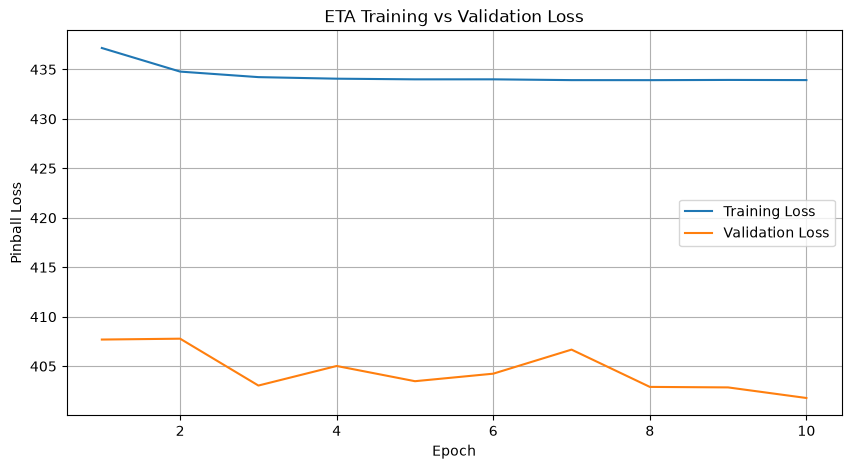

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(range(1, epochs + 1), epochs_train_loss, label="Training Loss")

plt.plot(range(1, epochs + 1), epochs_val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Pinball Loss")
plt.title("ETA Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


## Evaluate

Because individual mini-batches are noisy, I check the ~10% and ~90% coverage across all rows of your validation or test set (not just one batch):

In [15]:
model.eval()

with torch.inference_mode():
    test_preds = model(X_test_tensor)
    y_test_1d = y_test_tensor.reshape(-1)

    # preds has shape (N_val, 2), y_val has shape (N_val,)
    below_lower_rate = (y_test_1d < test_preds[:, 0]).float().mean().item()
    below_upper_rate = (y_test_1d <= test_preds[:, 1]).float().mean().item()

    print(f"Below lower (target ~0.10): {below_lower_rate:.2%}")
    print(f"At/below upper (target ~0.90): {below_upper_rate:.2%}")

Below lower (target ~0.10): 8.71%
At/below upper (target ~0.90): 87.94%


In [20]:
y_train_tensor.std()

tensor(21474.8594)

Your coverage numbers (`8.71%` and `87.94%`) are actually **pretty close to `10%` and `90%**`.

### 1. Checking Your Interpretation of `87.94%` and `8.71%`

* **`At/below upper: 87.94%`
It means **87.94% of test deliveries arrived at or before predicted upper bound** (and ~12.06% arrived later than the upper bound). For a `q = 0.90` target, **87.94%** is only ~2 percentage points below `90%`—that is actually quite close for 10 epochs.
* **`Below lower: 8.71%` is also close to `10%`.**
It means **8.71% of test deliveries arrived earlier than your predicted lower bound** (target is ~10%, so only ~1.3 percentage points off).